# How machines learn: classification

[Regression](regression.ipynb) predicted a number. Classification predicts a label. This notebook runs six classifiers on the same 2D dataset so their decision boundaries can be compared directly: kNN, logistic regression, a decision tree, a random forest, naive Bayes, and AdaBoost.

Recall from part one: **bias** is error from a model too simple for the pattern, **variance** is error from a model too sensitive to its particular training sample.

In [1]:
import inspect
import numpy as np
import matplotlib.pyplot as plt

def accuracy(y_true, y_pred):
    return np.mean(y_true == y_pred)

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def as_2d(X):
    X = np.asarray(X)
    return X.reshape(-1, 1) if X.ndim == 1 else X

def split(X, y, test_frac=0.3, seed=0):
    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(X))
    cut = int(len(X) * test_frac)
    test, train = idx[:cut], idx[cut:]
    return X[train], y[train], X[test], y[test]

## The dataset

Two Gaussian clusters in 2D, labeled 0 and 1, close enough that the classes overlap a little at the boundary. `plot_boundary` colors every point of the plane by the class a model would predict there, then draws the test points on top.

In [2]:
def make_blobs(n=200, seed=0):
    rng = np.random.default_rng(seed)
    n0, n1 = n // 2, n - n // 2
    class0 = rng.normal(loc=[-1.2, -1.2], scale=1.1, size=(n0, 2))
    class1 = rng.normal(loc=[1.6, 1.6], scale=1.1, size=(n1, 2))
    X = np.vstack([class0, class1])
    y = np.concatenate([np.zeros(n0), np.ones(n1)])
    return X, y

def plot_boundary(predict_fn, X, y, title):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
    zz = predict_fn(np.column_stack([xx.ravel(), yy.ravel()])).reshape(xx.shape)

    plt.figure(figsize=(5, 4))
    plt.contourf(xx, yy, zz, levels=[-0.5, 0.5, 1.5], alpha=0.3, colors=["#1f77b4", "#ff7f0e"])
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolor="k", s=20)
    plt.title(title)
    plt.show()

X_cls, y_cls = make_blobs()
Xcls_train, ycls_train, Xcls_test, ycls_test = split(X_cls, y_cls)
results = {}  # test accuracy per model, compared at the end

## kNN classifier

No training step at all: it just remembers the data. To classify a new point, find its `k` nearest neighbors by distance and take a majority vote among their labels. With 0/1 labels, the mean of the neighbors' labels is the fraction voting 1, so rounding it is the vote.

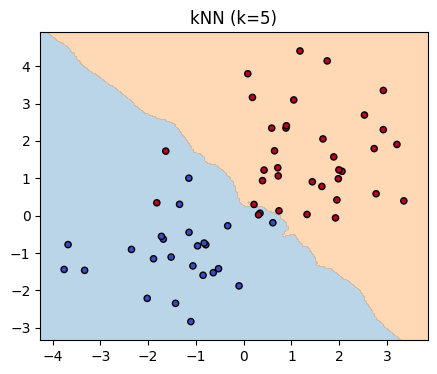

test accuracy: 0.95


In [3]:
class KNNClassifier:
    def __init__(self, k=5):
        self.k = k

    def fit(self, X, y):
        self.X_, self.y_ = X, y
        return self

    def predict(self, X):
        preds = np.empty(len(X))
        for i, row in enumerate(X):
            dists = np.linalg.norm(self.X_ - row, axis=1)
            nearest = self.y_[np.argsort(dists)[: self.k]]
            preds[i] = np.round(nearest.mean())
        return preds

knn = KNNClassifier(k=5).fit(Xcls_train, ycls_train)
plot_boundary(knn.predict, Xcls_test, ycls_test, "kNN (k=5)")
results["kNN"] = accuracy(ycls_test, knn.predict(Xcls_test))
print("test accuracy:", results["kNN"])

What to look for: a wiggly boundary that bends around individual training points near the overlap.

## Logistic regression

Fits a straight decision boundary by gradient descent on the cross-entropy loss. The linear score `w·x + b` goes through a sigmoid to become a probability between 0 and 1. Each step nudges the weights so that probability gets closer to the true label. It can only ever draw a straight line.

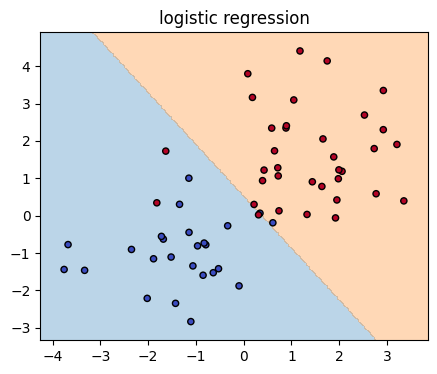

test accuracy: 0.9166666666666666


In [4]:
class LogisticRegression:
    def __init__(self, lr=0.1, epochs=500):
        self.lr = lr
        self.epochs = epochs

    def fit(self, X, y):
        Xb = np.column_stack([X, np.ones(len(X))])  # extra column of 1s for the bias term
        self.coef_ = np.zeros(Xb.shape[1])
        for _ in range(self.epochs):
            p = sigmoid(Xb @ self.coef_)
            self.coef_ -= self.lr * (Xb.T @ (p - y) / len(X))  # gradient of cross-entropy
        return self

    def predict_proba(self, X):
        Xb = np.column_stack([X, np.ones(len(X))])
        return sigmoid(Xb @ self.coef_)

    def predict(self, X):
        return (self.predict_proba(X) >= 0.5).astype(float)

logreg = LogisticRegression().fit(Xcls_train, ycls_train)
plot_boundary(logreg.predict, Xcls_test, ycls_test, "logistic regression")
results["logistic regression"] = accuracy(ycls_test, logreg.predict(Xcls_test))
print("test accuracy:", results["logistic regression"])

What to look for: one straight diagonal line. These two clusters happen to be close to linearly separable, so a straight line does well here.

## Decision tree classifier

The same recursive splitting as the regression tree in part one, adapted for labels. The `Tree` skeleton is repeated below so this notebook runs on its own.

At each node, try a cut at the median of each feature and keep whichever one reduces **Gini impurity** the most. Gini impurity measures how mixed a node is: 0 when every point has the same label, 0.5 when it's an even 50/50 split. A leaf predicts its majority class instead of a mean.

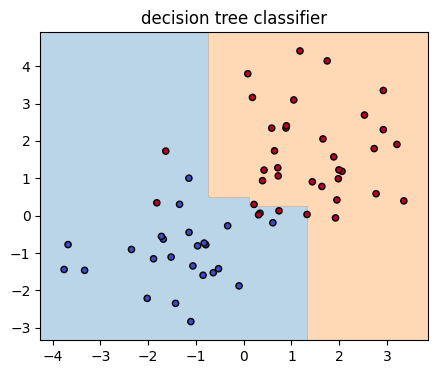

test accuracy: 0.9166666666666666


In [5]:
class Tree:
    """Shared skeleton: split the data in two, recurse on each side, stop at small or pure nodes.
    Subclasses only decide how to pick a split and what a leaf predicts."""

    def __init__(self, leaf_size=1):
        self.leaf_size = leaf_size

    def fit(self, X, y):
        self.tree_ = self._build(as_2d(X), y)
        return self

    def predict(self, X):
        return np.array([self._predict_row(row) for row in as_2d(X)])

    def _leaf_value(self, y):
        return y.mean()

    def _choose_split(self, X, y):
        """Return (feature, split value), or None to make this node a leaf."""
        raise NotImplementedError

    def _build(self, X, y):
        if len(y) <= self.leaf_size or np.all(y == y[0]):
            return {"leaf": True, "value": self._leaf_value(y)}

        choice = self._choose_split(X, y)
        if choice is None:
            return {"leaf": True, "value": self._leaf_value(y)}
        feat, split_val = choice
        left = X[:, feat] <= split_val
        if left.all() or (~left).all():  # split didn't separate anything
            return {"leaf": True, "value": self._leaf_value(y)}

        return {
            "leaf": False,
            "feature": feat,
            "split": split_val,
            "left": self._build(X[left], y[left]),
            "right": self._build(X[~left], y[~left]),
        }

    def _predict_row(self, row):
        node = self.tree_
        while not node["leaf"]:
            node = node["left"] if row[node["feature"]] <= node["split"] else node["right"]
        return node["value"]


def gini(y):
    if len(y) == 0:
        return 0.0
    p = y.mean()
    return 1 - p ** 2 - (1 - p) ** 2

class DecisionTreeClassifier(Tree):
    def __init__(self, leaf_size=5):
        super().__init__(leaf_size)

    def _leaf_value(self, y):
        return np.round(y.mean())  # majority class

    def _candidate_features(self, d):
        return range(d)

    def _choose_split(self, X, y):
        parent = gini(y)
        best, best_gain = None, 0.0
        for f in self._candidate_features(X.shape[1]):
            split_val = np.median(X[:, f])
            left = X[:, f] <= split_val
            # impurity after the split: each side's Gini, weighted by its share of the points
            child = left.mean() * gini(y[left]) + (~left).mean() * gini(y[~left])
            if parent - child > best_gain:
                best, best_gain = (f, split_val), parent - child
        return best  # None if no split reduces impurity

dtc = DecisionTreeClassifier(leaf_size=5).fit(Xcls_train, ycls_train)
plot_boundary(dtc.predict, Xcls_test, ycls_test, "decision tree classifier")
results["decision tree"] = accuracy(ycls_test, dtc.predict(Xcls_test))
print("test accuracy:", results["decision tree"])

What to look for: a boundary made only of horizontal and vertical segments, because every split cuts along one feature.

## Random forest

A random forest adds two ideas on top of the classifier tree:

1. **Bagging**: train each tree on a bootstrap sample and combine them by majority vote, as in part one.
2. **Random features**: at every split, each tree only considers a random subset of the features. With two features and `n_features=1`, each split is forced to use whichever feature it's handed.

The second idea makes the trees disagree with each other more. Averaging only cancels out errors if the trees make *different* errors.

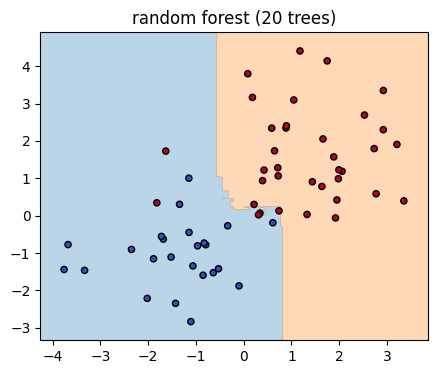

single tree test accuracy: 0.9166666666666666
forest test accuracy:      0.9333333333333333


In [6]:
class RandomForestTree(DecisionTreeClassifier):
    def __init__(self, leaf_size=5, n_features=1, seed=None):
        super().__init__(leaf_size)
        self.n_features = n_features
        self.rng = np.random.default_rng(seed)

    def _candidate_features(self, d):
        return self.rng.choice(d, size=min(self.n_features, d), replace=False)

class BagLearner:
    """Train n_bags copies of a learner on bootstrap samples and average their predictions.
    With classify=True and 0/1 labels, the average is the fraction voting 1, so
    thresholding it at 0.5 is a majority vote."""

    def __init__(self, learner_cls, n_bags=20, learner_kwargs=None, classify=False, seed=0):
        self.learner_cls = learner_cls
        self.n_bags = n_bags
        self.learner_kwargs = learner_kwargs or {}
        self.classify = classify
        self.rng = np.random.default_rng(seed)

    def fit(self, X, y):
        n = len(X)
        kwargs = dict(self.learner_kwargs)
        takes_seed = "seed" in inspect.signature(self.learner_cls).parameters
        self.learners_ = []
        for _ in range(self.n_bags):
            idx = self.rng.integers(0, n, n)  # n rows drawn with replacement
            if takes_seed:  # give randomized learners their own seed so runs are reproducible
                kwargs["seed"] = self.rng.integers(2**32)
            self.learners_.append(self.learner_cls(**kwargs).fit(X[idx], y[idx]))
        return self

    def predict(self, X):
        avg = np.mean([learner.predict(X) for learner in self.learners_], axis=0)
        return (avg >= 0.5).astype(float) if self.classify else avg


single_rf_tree = RandomForestTree(leaf_size=5, n_features=1, seed=0).fit(Xcls_train, ycls_train)
forest = BagLearner(RandomForestTree, n_bags=20, learner_kwargs={"leaf_size": 5, "n_features": 1},
                    classify=True, seed=0).fit(Xcls_train, ycls_train)

plot_boundary(forest.predict, Xcls_test, ycls_test, "random forest (20 trees)")
results["random forest"] = accuracy(ycls_test, forest.predict(Xcls_test))
print("single tree test accuracy:", accuracy(ycls_test, single_rf_tree.predict(Xcls_test)))
print("forest test accuracy:     ", results["random forest"])

What to look for: still made of axis-aligned steps, but many small ones, so the boundary approximates a diagonal better than a single tree.

## Naive Bayes

Assumes the two features are independent once you know the class, and models each one as a Gaussian. Fitting means computing a mean, variance, and prior (the fraction of points in that class) for each class. Predicting means scoring each class by how likely the point is under that class's Gaussians and picking the higher score. No iterative optimization anywhere.

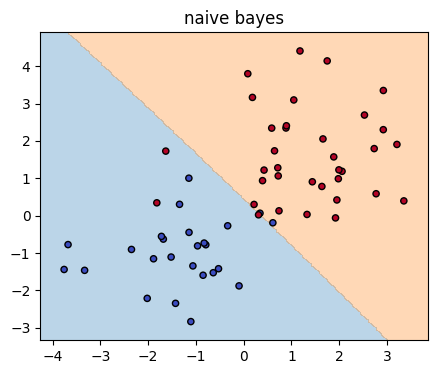

test accuracy: 0.9166666666666666


In [7]:
class GaussianNB:
    def fit(self, X, y):
        self.classes_ = np.unique(y)
        self.priors_, self.means_, self.vars_ = {}, {}, {}
        for c in self.classes_:
            X_class = X[y == c]
            self.priors_[c] = len(X_class) / len(X)
            self.means_[c] = X_class.mean(axis=0)
            self.vars_[c] = X_class.var(axis=0) + 1e-6
        return self

    def _log_likelihood(self, X, c):
        mean, var = self.means_[c], self.vars_[c]
        return -0.5 * np.sum(np.log(2 * np.pi * var)) - 0.5 * np.sum((X - mean) ** 2 / var, axis=1)

    def predict(self, X):
        scores = np.column_stack(
            [np.log(self.priors_[c]) + self._log_likelihood(X, c) for c in self.classes_]
        )
        return self.classes_[np.argmax(scores, axis=1)]

nb_model = GaussianNB().fit(Xcls_train, ycls_train)
plot_boundary(nb_model.predict, Xcls_test, ycls_test, "naive bayes")
results["naive bayes"] = accuracy(ycls_test, nb_model.predict(Xcls_test))
print("test accuracy:", results["naive bayes"])

What to look for: a smooth boundary, close to straight here because both classes have similar spreads. Where the spreads differ, the boundary curves.

## Boosting: AdaBoost

Bagging trains many learners independently on resampled data to cut down variance. Boosting trains learners one after another on the *same* data, but after each round it reweights the points so the next learner focuses on whatever the previous ones got wrong. That builds a strong model out of weak ones, which cuts down bias.

Each weak learner here is a **decision stump**: a tree with a single split. The final prediction is a weighted vote across all the stumps, where more accurate stumps get a bigger say.

AdaBoost's math is cleanest with labels of `+1` and `-1` instead of 1 and 0: then "correct" means `y * prediction = +1` and "wrong" means `-1`, so one formula raises the weight of wrong points and lowers the weight of right ones.

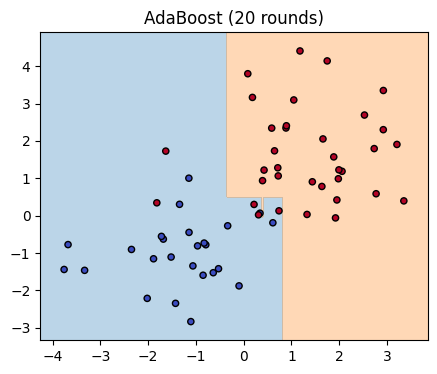

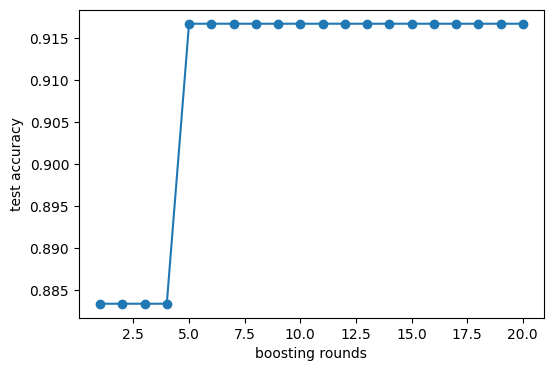

In [8]:
class DecisionStump:
    def fit(self, X, y, weights):
        best = (0, 0.0, 1, np.inf)  # feature, split, polarity, weighted error
        for f in range(X.shape[1]):
            for t in np.unique(X[:, f]):
                # polarity=1 predicts +1 below the split; polarity=-1 flips it to predict +1 above
                for polarity in (1, -1):
                    pred = np.where(polarity * X[:, f] <= polarity * t, 1, -1)
                    err = weights[pred != y].sum()
                    if err < best[3]:
                        best = (f, t, polarity, err)
        self.feature, self.split, self.polarity, _ = best
        return self

    def predict(self, X):
        return np.where(self.polarity * X[:, self.feature] <= self.polarity * self.split, 1, -1)

class AdaBoost:
    def __init__(self, n_rounds=20):
        self.n_rounds = n_rounds

    def fit(self, X, y):
        y_pm = np.where(y == 1, 1, -1)  # 0/1 labels -> -1/+1
        weights = np.full(len(X), 1 / len(X))
        self.stumps_, self.alphas_ = [], []
        for _ in range(self.n_rounds):
            stump = DecisionStump().fit(X, y_pm, weights)
            pred = stump.predict(X)
            err = np.clip(weights[pred != y_pm].sum(), 1e-10, 1 - 1e-10)
            alpha = 0.5 * np.log((1 - err) / err)  # this stump's vote: larger when err is small
            weights *= np.exp(-alpha * y_pm * pred)  # wrong points grow, right points shrink
            weights /= weights.sum()
            self.stumps_.append(stump)
            self.alphas_.append(alpha)
        return self

    def predict(self, X, n_rounds=None):
        n_rounds = len(self.stumps_) if n_rounds is None else n_rounds
        agg = sum(a * s.predict(X) for a, s in zip(self.alphas_[:n_rounds], self.stumps_[:n_rounds]))
        return np.where(agg >= 0, 1.0, 0.0)  # back to 0/1 labels

ada = AdaBoost(n_rounds=20).fit(Xcls_train, ycls_train)
plot_boundary(ada.predict, Xcls_test, ycls_test, "AdaBoost (20 rounds)")
results["AdaBoost"] = accuracy(ycls_test, ada.predict(Xcls_test))

rounds = range(1, 21)
accs = [accuracy(ycls_test, ada.predict(Xcls_test, n_rounds=r)) for r in rounds]
plt.figure(figsize=(6, 4))
plt.plot(rounds, accs, marker="o")
plt.xlabel("boosting rounds")
plt.ylabel("test accuracy")
plt.show()

What to look for: the boundary is built from straight cuts like a tree's, and the second plot shows how test accuracy changes as more stumps join the vote.

## Results

In [9]:
for name, score in sorted(results.items(), key=lambda kv: -kv[1]):
    print(f"{name:<22} {score:.3f}")

kNN                    0.950
random forest          0.933
logistic regression    0.917
decision tree          0.917
naive bayes            0.917
AdaBoost               0.917


# Summary

Logistic regression draws one straight boundary. kNN and the decision tree bend to fit the data directly, and can overfit near the overlap. Naive Bayes gets a smooth boundary with no iteration at all by assuming the features are independent. A random forest applies part one's bagging idea to classification trees, with random features to make the trees disagree. Boosting works the other way from bagging: it trains learners one after another on reweighted data, each fixing what came before, so it reduces bias rather than variance.

Part three, [unsupervised learning](unsupervised.ipynb), drops the labels entirely.